In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

In [ ]:
# ==========================================================
# PROJECT CONFIGURATION
# ==========================================================

GRADE_THRESHOLD = 10
RANDOM_STATE = 42

TEST_SIZE = 0.20
VALIDATION_SIZE = 0.25    # 25% of remaining training data

# Fairness intervention constraint:
# Fair model should retain at least 95% of baseline validation F1.
MIN_F1_FRACTION = 0.95

In [ ]:
# ==========================================================
# LOAD DATA
# ==========================================================

file_path = "student-por.csv"

df = pd.read_csv(file_path, sep=";")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (649, 33)

Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

First 5 rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,0,yes,no,no,no,yes,yes,yes,no,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,no,yes,yes,yes,yes,yes,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,no,no,yes,yes,no,no,4,3,2,1,2,5,0,11,13,13


In [ ]:
# ==========================================================
# BASIC EXPLORATION
# ==========================================================

print("Dataset shape:", df.shape)

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nData types:")
print(df.dtypes)

print("\nSex distribution:")
print(df["sex"].value_counts())

print("\nFinal grade distribution:")
print(df["G3"].value_counts().sort_index())

print("\nFinal grade statistics:")
print(df["G3"].describe())

Dataset shape: (649, 33)

Missing values:
school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64

Data types:
school        object
sex           object
age            int64
address       object
famsize       object
Pstatus       object
Medu           int64
Fedu           int64
Mjob          object
Fjob          object
reason        object
guardian      object
traveltime     int64
studytime      int64
failures       int64
schoolsup     object
famsup        object
paid          object
activities    object
nurse

In [ ]:
# ==========================================================
# CREATE BINARY TARGET
# ==========================================================

df["needs_support"] = (
    df["G3"] < GRADE_THRESHOLD
).astype(int)

print("Grade threshold:", GRADE_THRESHOLD)

print("\nTarget distribution:")
print(df["needs_support"].value_counts())

print("\nTarget proportion:")
print(df["needs_support"].value_counts(normalize=True))

Grade threshold: 10

Target distribution:
needs_support
0    549
1    100
Name: count, dtype: int64

Target proportion:
needs_support
0   0.8459
1   0.1541
Name: proportion, dtype: float64


In [ ]:
# ==========================================================
# TARGET DISTRIBUTION BY SEX
# ==========================================================

sex_target = pd.crosstab(
    df["sex"],
    df["needs_support"],
    normalize="index"
)

sex_target.columns = ["Does not need support", "Needs support"]

print(sex_target)

print("\nNumber of students by sex and target:")
display(
    pd.crosstab(
        df["sex"],
        df["needs_support"]
    )
)

     Does not need support  Needs support
sex                                      
F                   0.8695         0.1305
M                   0.8120         0.1880

Number of students by sex and target:


needs_support,0,1
sex,,
F,333,50
M,216,50


In [ ]:
# ==========================================================
# CREATE FEATURES AND TARGET
# ==========================================================

# G3 is used only to create the target.
# G1 and G2 are explicitly removed to prevent target leakage.

X = df.drop(
    columns=[
        "G1",
        "G2",
        "G3",
        "needs_support"
    ]
)

y = df["needs_support"]

print("Number of features used:", X.shape[1])

print("\nFeatures used:")
print(X.columns.tolist())

Number of features used: 30

Features used:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']


In [ ]:
# ==========================================================
# TRAIN / VALIDATION / TEST SPLIT
# ==========================================================

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=VALIDATION_SIZE,
    stratify=y_train_full,
    random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True))

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))

Training set: (389, 30)
Validation set: (130, 30)
Test set: (130, 30)

Training target distribution:
needs_support
0   0.8458
1   0.1542
Name: proportion, dtype: float64

Validation target distribution:
needs_support
0   0.8462
1   0.1538
Name: proportion, dtype: float64

Test target distribution:
needs_support
0   0.8462
1   0.1538
Name: proportion, dtype: float64


In [ ]:
# ==========================================================
# IDENTIFY FEATURE TYPES
# ==========================================================

categorical_cols = X_train.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numeric_cols = X_train.select_dtypes(
    include=[np.number]
).columns.tolist()

print("Numerical features:")
print(numeric_cols)

print("\nCategorical features:")
print(categorical_cols)

Numerical features:
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences']

Categorical features:
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']


In [ ]:
# ==========================================================
# PREPROCESSING PIPELINE
# ==========================================================

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

In [ ]:
# ==========================================================
# LOGISTIC REGRESSION MODEL
# ==========================================================

model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", LogisticRegression(
        max_iter=2000,
        solver="liblinear",
        random_state=RANDOM_STATE
    ))
])

model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


In [ ]:
# ==========================================================
# PREDICT PROBABILITIES
# ==========================================================

val_prob = model.predict_proba(X_val)[:, 1]
test_prob = model.predict_proba(X_test)[:, 1]

print("Example validation probabilities:")
print(val_prob[:10])

Example validation probabilities:
[0.01453903 0.01215634 0.00292988 0.04953198 0.01891293 0.00349825
 0.04437148 0.11247056 0.00886506 0.00218611]


In [ ]:
# ==========================================================
# EVALUATION FUNCTIONS
# ==========================================================

def overall_metrics(y_true, y_prob, threshold):
    """
    Calculate overall predictive performance.
    """

    y_pred = (y_prob >= threshold).astype(int)

    return pd.Series({
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, zero_division=0
        ),
        "F1": f1_score(
            y_true, y_pred, zero_division=0
        ),
        "ROC_AUC": roc_auc_score(y_true, y_prob),
        "PR_AUC": average_precision_score(y_true, y_prob)
    })


def group_metrics(X_eval, y_true, y_pred):
    """
    Calculate fairness-related metrics separately for each sex group.
    """

    evaluation = X_eval.copy()

    evaluation["_actual"] = np.asarray(y_true)
    evaluation["_predicted"] = np.asarray(y_pred)

    results = []

    for group in sorted(evaluation["sex"].unique()):

        group_data = evaluation[
            evaluation["sex"] == group
        ]

        tn, fp, fn, tp = confusion_matrix(
            group_data["_actual"],
            group_data["_predicted"],
            labels=[0, 1]
        ).ravel()

        actual_positive = tp + fn
        actual_negative = tn + fp

        tpr = (
            tp / actual_positive
            if actual_positive > 0 else np.nan
        )

        fnr = (
            fn / actual_positive
            if actual_positive > 0 else np.nan
        )

        fpr = (
            fp / actual_negative
            if actual_negative > 0 else np.nan
        )

        specificity = (
            tn / actual_negative
            if actual_negative > 0 else np.nan
        )

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0 else np.nan
        )

        results.append({
            "Sex": group,
            "N": len(group_data),
            "Actual_support_rate": group_data["_actual"].mean(),
            "Support_allocation_rate": group_data["_predicted"].mean(),
            "TPR": tpr,
            "FNR": fnr,
            "FPR": fpr,
            "Specificity": specificity,
            "Precision": precision
        })

    return pd.DataFrame(results).set_index("Sex")


def fairness_gaps(group_result):
    """
    Calculate absolute disparities between female and male groups.
    """

    female = group_result.loc["F"]
    male = group_result.loc["M"]

    return pd.Series({
        "TPR_gap": abs(female["TPR"] - male["TPR"]),
        "FNR_gap": abs(female["FNR"] - male["FNR"]),
        "FPR_gap": abs(female["FPR"] - male["FPR"]),
        "Precision_gap": abs(
            female["Precision"] - male["Precision"]
        ),
        "Support_rate_gap": abs(
            female["Support_allocation_rate"]
            - male["Support_allocation_rate"]
        )
    })

In [ ]:
# ==========================================================
# BASELINE THRESHOLD SELECTION
# ==========================================================

def choose_global_threshold(
    y_true,
    probabilities,
    thresholds=None
):
    """
    Select one common threshold using validation F1.
    """

    if thresholds is None:
        thresholds = np.arange(0.01, 1.00, 0.01)

    candidates = []

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        f1 = f1_score(
            y_true,
            predictions,
            zero_division=0
        )

        # Second criterion keeps threshold reasonably near 0.5
        distance_from_half = abs(
            threshold - 0.5
        )

        candidates.append(
            (f1, -distance_from_half, threshold)
        )

    best = max(candidates)

    return best[2]


baseline_threshold = choose_global_threshold(
    y_val,
    val_prob
)

baseline_validation_metrics = overall_metrics(
    y_val,
    val_prob,
    baseline_threshold
)

baseline_validation_f1 = (
    baseline_validation_metrics["F1"]
)

print(
    f"Baseline threshold: "
    f"{baseline_threshold:.2f}"
)

display(baseline_validation_metrics)

Baseline threshold: 0.29


,0
Accuracy,0.8154
Precision,0.4091
Recall,0.4500
F1,0.4286
ROC_AUC,0.7086
PR_AUC,0.3245


In [ ]:
# ==========================================================
# BASELINE TEST PREDICTIONS
# ==========================================================

baseline_test_pred = (
    test_prob >= baseline_threshold
).astype(int)

baseline_overall = overall_metrics(
    y_test,
    test_prob,
    baseline_threshold
)

print("BASELINE MODEL PERFORMANCE")
display(baseline_overall)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        baseline_test_pred,
        target_names=[
            "No support",
            "Needs support"
        ],
        zero_division=0
    )
)

BASELINE MODEL PERFORMANCE


,0
Accuracy,0.7846
Precision,0.3000
Recall,0.3000
F1,0.3000
ROC_AUC,0.7523
PR_AUC,0.3233



Classification report:
               precision    recall  f1-score   support

   No support       0.87      0.87      0.87       110
Needs support       0.30      0.30      0.30        20

     accuracy                           0.78       130
    macro avg       0.59      0.59      0.59       130
 weighted avg       0.78      0.78      0.78       130



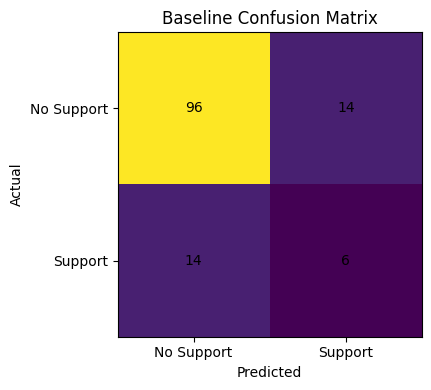

In [ ]:
# ==========================================================
# BASELINE CONFUSION MATRIX
# ==========================================================

cm = confusion_matrix(
    y_test,
    baseline_test_pred
)

fig, ax = plt.subplots(figsize=(5, 4))

ax.imshow(cm)

ax.set_title("Baseline Confusion Matrix")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    "No Support",
    "Support"
])

ax.set_yticklabels([
    "No Support",
    "Support"
])

for i in range(2):
    for j in range(2):
        ax.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center"
        )

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================================
# BASELINE FAIRNESS
# ==========================================================

baseline_group = group_metrics(
    X_test,
    y_test,
    baseline_test_pred
)

print("Baseline group metrics:")
display(baseline_group)

baseline_gaps = fairness_gaps(
    baseline_group
)

print("\nBaseline fairness gaps:")
display(baseline_gaps)

Baseline group metrics:


,N,Actual_support_rate,Support_allocation_rate,TPR,FNR,FPR,Specificity,Precision
Sex,,,,,,,,
F,80,0.1250,0.1500,0.4000,0.6000,0.1143,0.8857,0.3333
M,50,0.2000,0.1600,0.2000,0.8000,0.1500,0.8500,0.2500



Baseline fairness gaps:


,0
TPR_gap,0.2000
FNR_gap,0.2000
FPR_gap,0.0357
Precision_gap,0.0833
Support_rate_gap,0.0100


In [ ]:
# ==========================================================
# SHAP PREPARATION
# ==========================================================

trained_preprocessor = (
    model.named_steps["preprocessor"]
)

trained_classifier = (
    model.named_steps["classifier"]
)

X_train_transformed = (
    trained_preprocessor.transform(X_train)
)

X_test_transformed = (
    trained_preprocessor.transform(X_test)
)

feature_names = (
    trained_preprocessor
    .get_feature_names_out()
)

X_test_transformed_df = pd.DataFrame(
    X_test_transformed,
    columns=feature_names,
    index=X_test.index
)

print(
    "Number of transformed features:",
    len(feature_names)
)

Number of transformed features: 56


In [ ]:
# ==========================================================
# SHAP GLOBAL EXPLANATION
# ==========================================================

explainer = shap.LinearExplainer(
    trained_classifier,
    X_train_transformed
)

shap_values = explainer(
    X_test_transformed_df
)

print(
    "SHAP matrix shape:",
    shap_values.values.shape
)

SHAP matrix shape: (130, 56)


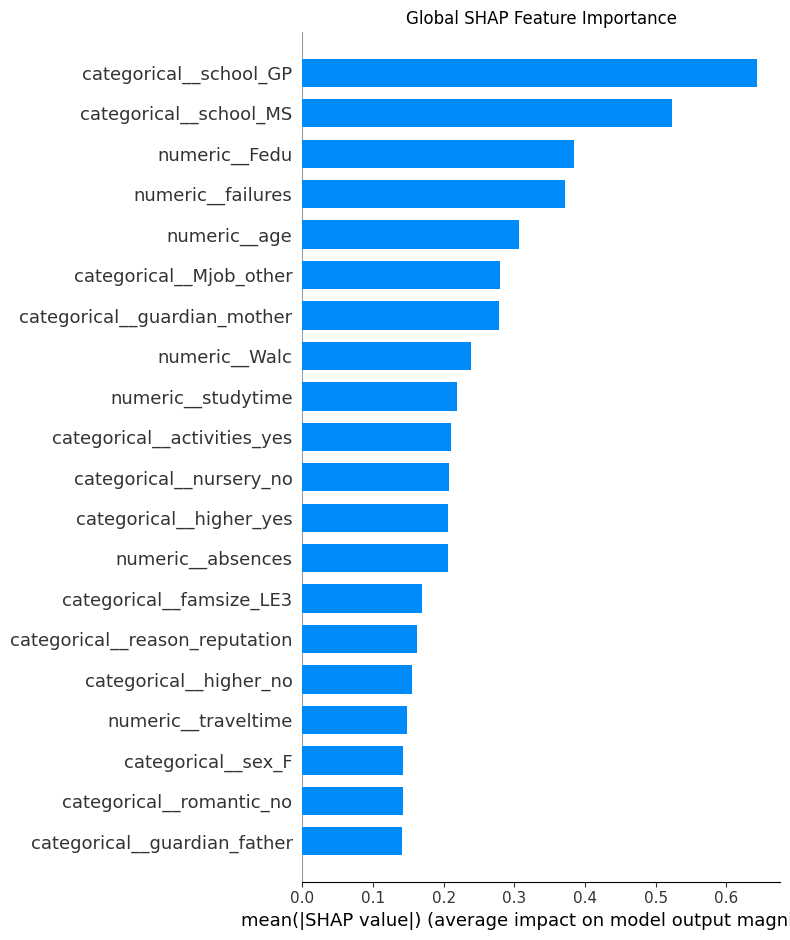

In [ ]:
# ==========================================================
# GLOBAL SHAP IMPORTANCE
# ==========================================================

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values.values,
    X_test_transformed_df,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.title(
    "Global SHAP Feature Importance"
)

plt.tight_layout()
plt.show()

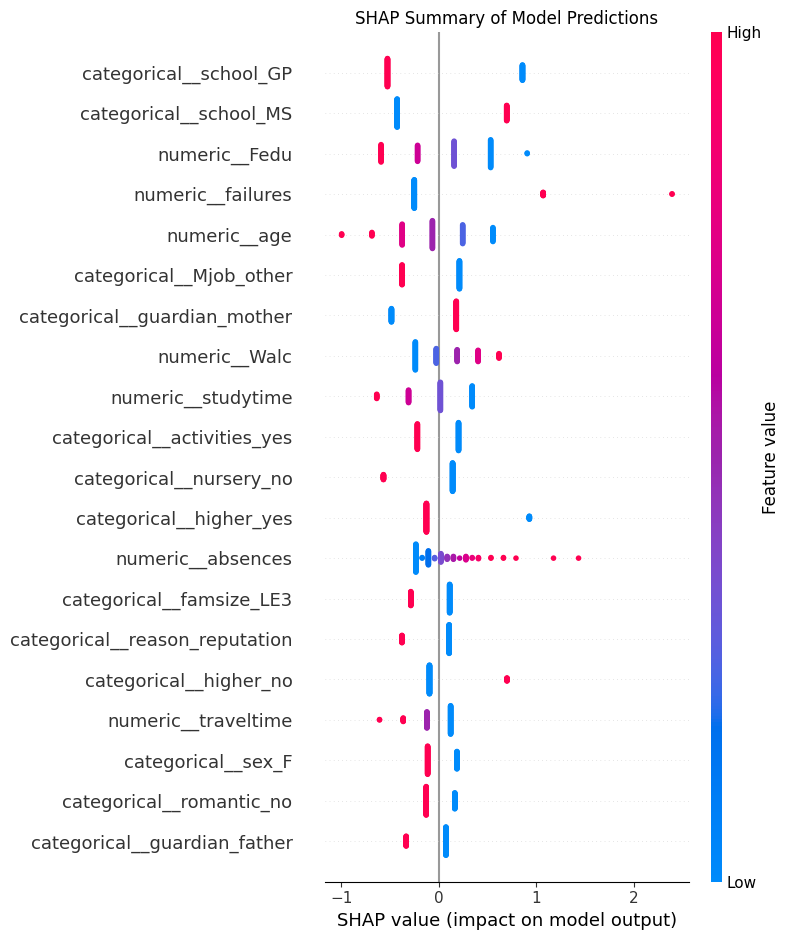

In [ ]:
# ==========================================================
# SHAP DETAILED SUMMARY
# ==========================================================

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values.values,
    X_test_transformed_df,
    feature_names=feature_names,
    show=False
)

plt.title(
    "SHAP Summary of Model Predictions"
)

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================================
# LOCAL SHAP EXPLANATION
# ==========================================================

# Find students who were predicted to need support
support_indices = np.where(
    baseline_test_pred == 1
)[0]

if len(support_indices) > 0:

    local_position = support_indices[0]

else:

    local_position = 0

print("Student index:", X_test.index[local_position])

print("\nOriginal student information:")
display(
    X_test.loc[
        X_test.index[local_position]
    ].to_frame().T
)

print(
    "\nPredicted probability of needing support:",
    f"{test_prob[local_position]:.4f}"
)

print(
    "Predicted decision:",
    "NEEDS SUPPORT"
    if baseline_test_pred[local_position] == 1
    else "NO SUPPORT"
)

Student index: 627

Original student information:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences
627,MS,M,18,R,LE3,T,1,2,at_home,services,other,father,3,1,0,no,yes,no,yes,yes,no,yes,yes,4,3,3,2,3,3,3



Predicted probability of needing support: 0.3894
Predicted decision: NEEDS SUPPORT


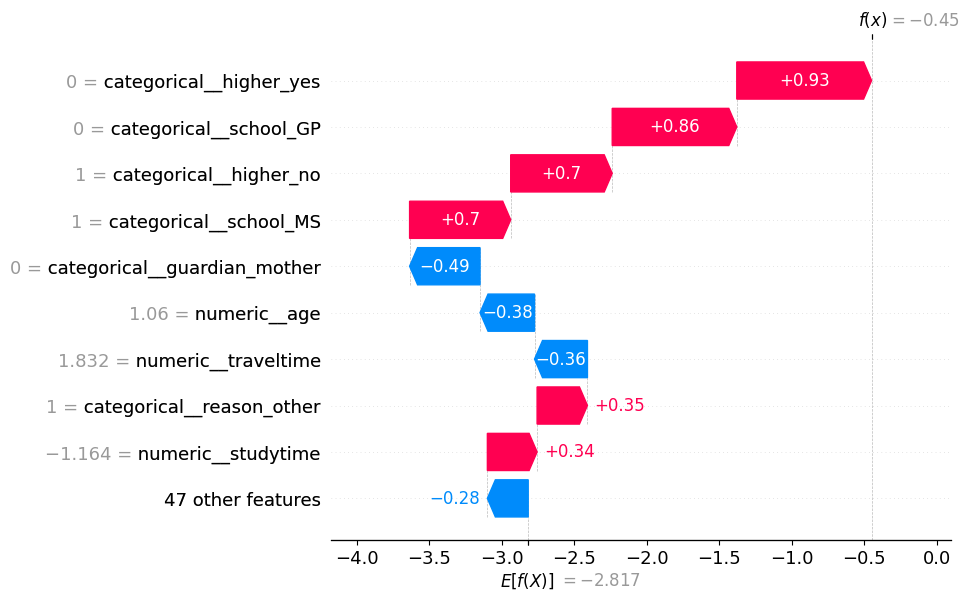

In [ ]:
# ==========================================================
# LOCAL SHAP WATERFALL
# ==========================================================

shap.plots.waterfall(
    shap_values[local_position],
    max_display=10
)

In [ ]:
# ==========================================================
# SHAP BY SEX
# ==========================================================

shap_df = pd.DataFrame(
    np.abs(shap_values.values),
    columns=feature_names,
    index=X_test.index
)

shap_df["sex"] = X_test["sex"]

female_shap = (
    shap_df[shap_df["sex"] == "F"]
    .drop(columns="sex")
    .mean()
    .sort_values(ascending=False)
)

male_shap = (
    shap_df[shap_df["sex"] == "M"]
    .drop(columns="sex")
    .mean()
    .sort_values(ascending=False)
)

shap_comparison = pd.DataFrame({
    "Female_mean_abs_SHAP": female_shap,
    "Male_mean_abs_SHAP": male_shap
})

shap_comparison["Absolute_difference"] = (
    abs(
        shap_comparison["Female_mean_abs_SHAP"]
        - shap_comparison["Male_mean_abs_SHAP"]
    )
)

display(
    shap_comparison.sort_values(
        "Absolute_difference",
        ascending=False
    ).head(15)
)

,Female_mean_abs_SHAP,Male_mean_abs_SHAP,Absolute_difference
numeric__failures,0.3332,0.4353,0.1021
numeric__Walc,0.2034,0.2973,0.0939
numeric__age,0.2750,0.3591,0.0841
categorical__sex_F,0.1143,0.1864,0.0722
categorical__higher_yes,0.1869,0.2391,0.0522
categorical__school_GP,0.6634,0.6127,0.0507
categorical__Mjob_health,0.0645,0.1136,0.0491
numeric__absences,0.1906,0.2323,0.0417
categorical__school_MS,0.5384,0.4973,0.0411
categorical__higher_no,0.1407,0.1800,0.0393


In [ ]:
# ==========================================================
# GROUP-SPECIFIC FAIRNESS INTERVENTION
# ==========================================================

def group_specific_predictions(
    X_eval,
    probabilities,
    female_threshold,
    male_threshold
):
    """
    Generate predictions using different thresholds
    for female and male students.
    """

    sex_values = X_eval["sex"].to_numpy()

    thresholds = np.where(
        sex_values == "F",
        female_threshold,
        male_threshold
    )

    return (
        probabilities >= thresholds
    ).astype(int)

In [ ]:
# ==========================================================
# SEARCH FOR FAIR THRESHOLDS
# ==========================================================

def search_fair_thresholds(
    X_val,
    y_val,
    probabilities,
    baseline_f1,
    min_f1_fraction=0.95,
    thresholds=None
):
    """
    Find group-specific thresholds that minimize
    the TPR gap while preserving a specified fraction
    of baseline validation F1.
    """

    if thresholds is None:
        thresholds = np.arange(
            0.01,
            1.00,
            0.01
        )

    candidates = []

    minimum_allowed_f1 = (
        baseline_f1 * min_f1_fraction
    )

    for female_threshold in thresholds:

        for male_threshold in thresholds:

            predictions = group_specific_predictions(
                X_val,
                probabilities,
                female_threshold,
                male_threshold
            )

            f1 = f1_score(
                y_val,
                predictions,
                zero_division=0
            )

            # Performance constraint
            if f1 < minimum_allowed_f1:
                continue

            group_result = group_metrics(
                X_val,
                y_val,
                predictions
            )

            female_tpr = group_result.loc[
                "F", "TPR"
            ]

            male_tpr = group_result.loc[
                "M", "TPR"
            ]

            # Skip invalid configurations
            if pd.isna(female_tpr) or pd.isna(male_tpr):
                continue

            tpr_gap = abs(
                female_tpr - male_tpr
            )

            distance_from_half = (
                abs(female_threshold - 0.5)
                + abs(male_threshold - 0.5)
            )

            candidates.append({
                "TPR_gap": tpr_gap,
                "F1": f1,
                "Female_threshold": female_threshold,
                "Male_threshold": male_threshold,
                "Distance_from_0.5": distance_from_half
            })

    if len(candidates) == 0:
        raise RuntimeError(
            "No threshold combination satisfied the "
            "validation F1 constraint."
        )

    candidates_df = pd.DataFrame(candidates)

    # Primary objective = smallest TPR gap
    # Secondary = highest F1
    # Tertiary = thresholds closer to 0.5

    candidates_df = candidates_df.sort_values(
        by=[
            "TPR_gap",
            "F1",
            "Distance_from_0.5"
        ],
        ascending=[
            True,
            False,
            True
        ]
    )

    best = candidates_df.iloc[0]

    return best, candidates_df

In [ ]:
# ==========================================================
# FIND FAIR THRESHOLDS
# ==========================================================

best_fair_thresholds, threshold_search = (
    search_fair_thresholds(
        X_val,
        y_val,
        val_prob,
        baseline_validation_f1,
        min_f1_fraction=MIN_F1_FRACTION
    )
)

female_threshold = (
    best_fair_thresholds["Female_threshold"]
)

male_threshold = (
    best_fair_thresholds["Male_threshold"]
)

print(
    f"Baseline threshold: "
    f"{baseline_threshold:.2f}"
)

print(
    f"Fairness-adjusted female threshold: "
    f"{female_threshold:.2f}"
)

print(
    f"Fairness-adjusted male threshold: "
    f"{male_threshold:.2f}"
)

print(
    f"Validation TPR gap after intervention: "
    f"{best_fair_thresholds['TPR_gap']:.4f}"
)

print(
    f"Validation F1 after intervention: "
    f"{best_fair_thresholds['F1']:.4f}"
)

Baseline threshold: 0.29
Fairness-adjusted female threshold: 0.42
Fairness-adjusted male threshold: 0.29
Validation TPR gap after intervention: 0.0101
Validation F1 after intervention: 0.4390


In [ ]:
# ==========================================================
# FAIRNESS-ADJUSTED TEST PREDICTIONS
# ==========================================================

fair_test_pred = group_specific_predictions(
    X_test,
    test_prob,
    female_threshold,
    male_threshold
)

print(
    "Fairness-adjusted predictions generated."
)

Fairness-adjusted predictions generated.


In [ ]:
# ==========================================================
# FAIRNESS-ADJUSTED PERFORMANCE
# ==========================================================

fair_overall = overall_metrics(
    y_test,
    test_prob,
    threshold=0.5
)

# The overall_metrics function assumes one threshold,
# so calculate the threshold-dependent metrics manually.

fair_overall = pd.Series({
    "Accuracy": accuracy_score(
        y_test,
        fair_test_pred
    ),

    "Precision": precision_score(
        y_test,
        fair_test_pred,
        zero_division=0
    ),

    "Recall": recall_score(
        y_test,
        fair_test_pred,
        zero_division=0
    ),

    "F1": f1_score(
        y_test,
        fair_test_pred,
        zero_division=0
    ),

    "ROC_AUC": roc_auc_score(
        y_test,
        test_prob
    ),

    "PR_AUC": average_precision_score(
        y_test,
        test_prob
    )
})

print("FAIRNESS-ADJUSTED MODEL PERFORMANCE")
display(fair_overall)

FAIRNESS-ADJUSTED MODEL PERFORMANCE


,0
Accuracy,0.8154
Precision,0.3750
Recall,0.3000
F1,0.3333
ROC_AUC,0.7523
PR_AUC,0.3233


In [ ]:
# ==========================================================
# FAIRNESS AFTER INTERVENTION
# ==========================================================

fair_group = group_metrics(
    X_test,
    y_test,
    fair_test_pred
)

print("Fairness-adjusted group metrics:")
display(fair_group)

fair_gaps = fairness_gaps(
    fair_group
)

print("\nFairness-adjusted gaps:")
display(fair_gaps)

Fairness-adjusted group metrics:


,N,Actual_support_rate,Support_allocation_rate,TPR,FNR,FPR,Specificity,Precision
Sex,,,,,,,,
F,80,0.1250,0.1000,0.4000,0.6000,0.0571,0.9429,0.5000
M,50,0.2000,0.1600,0.2000,0.8000,0.1500,0.8500,0.2500



Fairness-adjusted gaps:


,0
TPR_gap,0.2000
FNR_gap,0.2000
FPR_gap,0.0929
Precision_gap,0.2500
Support_rate_gap,0.0600


In [ ]:
# ==========================================================
# BASELINE VS FAIR MODEL
# ==========================================================

comparison = pd.DataFrame({
    "Baseline": baseline_overall,
    "Fairness_Adjusted": fair_overall
})

comparison["Change"] = (
    comparison["Fairness_Adjusted"]
    - comparison["Baseline"]
)

display(comparison)

,Baseline,Fairness_Adjusted,Change
Accuracy,0.7846,0.8154,0.0308
Precision,0.3000,0.3750,0.0750
Recall,0.3000,0.3000,0.0000
F1,0.3000,0.3333,0.0333
ROC_AUC,0.7523,0.7523,0.0000
PR_AUC,0.3233,0.3233,0.0000


In [ ]:
# ==========================================================
# FAIRNESS COMPARISON
# ==========================================================

fairness_comparison = pd.DataFrame({
    "Baseline": baseline_gaps,
    "Fairness_Adjusted": fair_gaps
})

fairness_comparison["Change"] = (
    fairness_comparison["Fairness_Adjusted"]
    - fairness_comparison["Baseline"]
)

display(fairness_comparison)

,Baseline,Fairness_Adjusted,Change
TPR_gap,0.2000,0.2000,0.0000
FNR_gap,0.2000,0.2000,0.0000
FPR_gap,0.0357,0.0929,0.0571
Precision_gap,0.0833,0.2500,0.1667
Support_rate_gap,0.0100,0.0600,0.0500


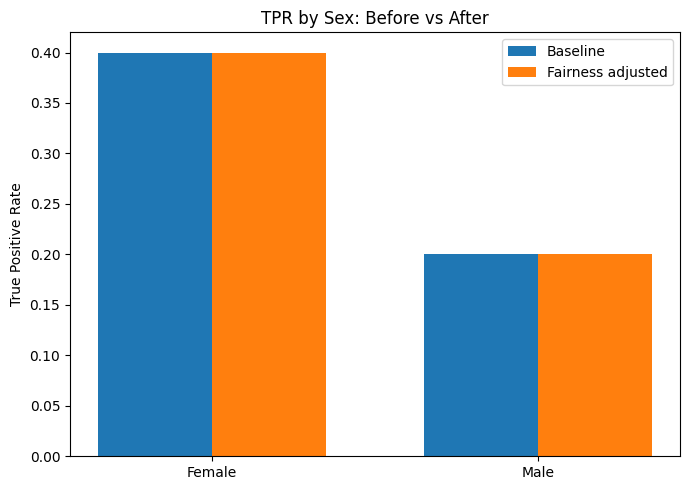

In [ ]:
# ==========================================================
# TPR COMPARISON
# ==========================================================

groups = ["F", "M"]

baseline_tpr = [
    baseline_group.loc[g, "TPR"]
    for g in groups
]

fair_tpr = [
    fair_group.loc[g, "TPR"]
    for g in groups
]

x = np.arange(len(groups))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(
    x - width / 2,
    baseline_tpr,
    width,
    label="Baseline"
)

ax.bar(
    x + width / 2,
    fair_tpr,
    width,
    label="Fairness adjusted"
)

ax.set_ylabel("True Positive Rate")
ax.set_title("TPR by Sex: Before vs After")
ax.set_xticks(x)
ax.set_xticklabels(["Female", "Male"])
ax.legend()

plt.tight_layout()
plt.show()

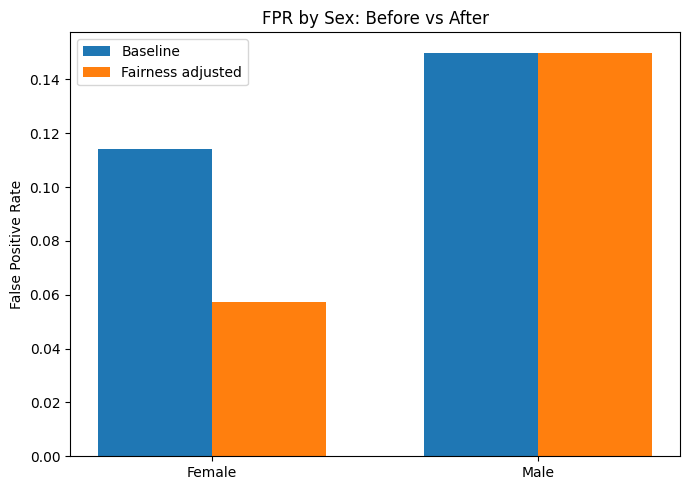

In [ ]:
# ==========================================================
# FPR COMPARISON
# ==========================================================

baseline_fpr = [
    baseline_group.loc[g, "FPR"]
    for g in groups
]

fair_fpr = [
    fair_group.loc[g, "FPR"]
    for g in groups
]

fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(
    x - width / 2,
    baseline_fpr,
    width,
    label="Baseline"
)

ax.bar(
    x + width / 2,
    fair_fpr,
    width,
    label="Fairness adjusted"
)

ax.set_ylabel("False Positive Rate")
ax.set_title("FPR by Sex: Before vs After")
ax.set_xticks(x)
ax.set_xticklabels(["Female", "Male"])
ax.legend()

plt.tight_layout()
plt.show()

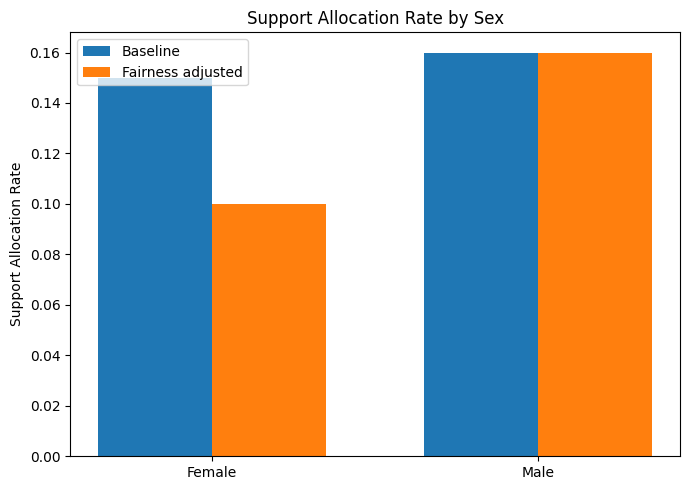

In [ ]:
# ==========================================================
# SUPPORT ALLOCATION RATE
# ==========================================================

baseline_support_rate = [
    baseline_group.loc[g, "Support_allocation_rate"]
    for g in groups
]

fair_support_rate = [
    fair_group.loc[g, "Support_allocation_rate"]
    for g in groups
]

fig, ax = plt.subplots(figsize=(7, 5))

ax.bar(
    x - width / 2,
    baseline_support_rate,
    width,
    label="Baseline"
)

ax.bar(
    x + width / 2,
    fair_support_rate,
    width,
    label="Fairness adjusted"
)

ax.set_ylabel("Support Allocation Rate")
ax.set_title(
    "Support Allocation Rate by Sex"
)
ax.set_xticks(x)
ax.set_xticklabels(["Female", "Male"])
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================================
# OPTIONAL RANDOM FOREST MODEL
# ==========================================================

from sklearn.ensemble import RandomForestClassifier

rf_model = Pipeline([
    ("preprocessor", preprocessor),

    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        class_weight=None
    ))
])

rf_model.fit(
    X_train,
    y_train
)

rf_test_prob = (
    rf_model.predict_proba(X_test)[:, 1]
)

rf_test_pred = (
    rf_test_prob >= baseline_threshold
).astype(int)

rf_metrics = overall_metrics(
    y_test,
    rf_test_prob,
    baseline_threshold
)

print("Random Forest performance:")
display(rf_metrics)

Random Forest performance:


,0
Accuracy,0.8308
Precision,0.4500
Recall,0.4500
F1,0.4500
ROC_AUC,0.8286
PR_AUC,0.4392


In [ ]:
model_comparison = pd.DataFrame({
    "Logistic Regression": baseline_overall,
    "Random Forest": rf_metrics
})

display(model_comparison)

,Logistic Regression,Random Forest
Accuracy,0.7846,0.8308
Precision,0.3000,0.4500
Recall,0.3000,0.4500
F1,0.3000,0.4500
ROC_AUC,0.7523,0.8286
PR_AUC,0.3233,0.4392


In [ ]:
# ==========================================================
# SAVE RESULTS
# ==========================================================

baseline_overall.to_csv(
    "baseline_overall_metrics.csv"
)

fair_overall.to_csv(
    "fairness_adjusted_overall_metrics.csv"
)

baseline_group.to_csv(
    "baseline_group_fairness.csv"
)

fair_group.to_csv(
    "fairness_adjusted_group_fairness.csv"
)

comparison.to_csv(
    "model_performance_comparison.csv"
)

fairness_comparison.to_csv(
    "fairness_comparison.csv"
)

shap_comparison.to_csv(
    "shap_by_sex.csv"
)

print("Results saved.")

Results saved.
